# DAB111: Introduction to Python Programming
## Course Project — Week 1: Dataset Selection and Exploratory Data Analysis (EDA)
**Project Title:** End-to-End Data Analysis and Web Application Development Using Python  
**Student Name:** Rushabh Mahesh Sanghvi  
**Student ID:** 0899550  
**Program:** Predictive Data Analytics (B021)  
**Academic Term:** Fall 2026  
**Institution:** St. Clair College, Windsor, ON  
**Dataset Selected:** Global Superstore / Retail Sales Dataset (`Sample_Superstore.csv`)

---

### Project Overview & Week 1 Objectives
The overarching objective of this 4-week project is to build an end-to-end data analytics workflow and web application. In Week 1, we focus on:
1. Selecting and loading a rich, real-world business dataset using **Pandas**.
2. Performing baseline structural exploration (`shape`, `head`, `tail`, `info`, `describe`, `nunique`).
3. Auditing data quality, identifying missing values, detecting duplicate rows, and establishing a cleaning strategy for Week 2.
4. Conducting at least five meaningful analytical investigations to uncover business patterns.
5. Creating at least four compelling data visualizations using **Matplotlib** and **Seaborn**.
6. Synthesizing findings to guide database normalization (SQLite) and web app development (Flask) in upcoming weeks.

## Step 1 & 2: Environment Setup and Loading Dataset
We import essential data manipulation and visualization libraries (`pandas`, `numpy`, `matplotlib`, `seaborn`) and load the `Sample_Superstore.csv` file.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Set aesthetic styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.size'] = 10

# Load dataset
import os
dataset_path = 'original_dataset.csv' if os.path.exists('original_dataset.csv') else 'Sample_Superstore.csv'
df = pd.read_csv(dataset_path, encoding='latin1')

print(f"Dataset successfully loaded. Total rows: {df.shape[0]}, Total columns: {df.shape[1]}")
df.head()

Dataset successfully loaded. Total rows: 10800, Total columns: 21


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


## Step 3: Exploring the Dataset Structure
We utilize standard Pandas inspection methods to understand schema dimensions, data types, column distributions, and random samples.

In [2]:
# Display last 5 records
df.tail()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
10795,Yes,US-2018-147886,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10796,Yes,US-2018-147998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10797,Yes,US-2018-151127,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10798,Yes,US-2018-155999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10799,Yes,US-2018-155999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
# Inspect dimensions and column names
print("Dimensions (Rows, Columns):", df.shape)
print("\nColumn Names:")
for i, col in enumerate(df.columns, 1):
    print(f" {i:2d}. {col}")

Dimensions (Rows, Columns): (10800, 21)

Column Names:
  1. Row ID
  2. Order ID
  3. Order Date
  4. Ship Date
  5. Ship Mode
  6. Customer ID
  7. Customer Name
  8. Segment
  9. Country
 10. City
 11. State
 12. Postal Code
 13. Region
 14. Product ID
 15. Category
 16. Sub-Category
 17. Product Name
 18. Sales
 19. Quantity
 20. Discount
 21. Profit


In [4]:
# Dataset Information and Data Types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10800 non-null  str    
 1   Order ID       10800 non-null  str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9983 non-null   float64
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       99

In [5]:
# Statistical Summary of Numeric Variables
df.describe()

,Postal Code,Sales,Quantity,Discount,Profit
count,9983.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,55245.233297,229.858001,3.789574,0.156203,28.656896
std,32038.715955,623.245101,2.225110,0.206452,234.260108
min,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,57103.000000,54.490000,3.000000,0.200000,8.666500
75%,90008.000000,209.940000,5.000000,0.200000,29.364000
max,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [6]:
# Unique values count per column
df.nunique()

Row ID           10001
Order ID          5015
Order Date        1236
Ship Date         1334
Ship Mode            4
Customer ID        793
Customer Name      793
Segment              3
Country              1
City               531
State               49
Postal Code        630
Region               4
Product ID        1862
Category             3
Sub-Category        17
Product Name      1850
Sales             5825
Quantity            14
Discount            12
Profit            7287
dtype: int64

In [7]:
# Display 10 random sample records
df.sample(10, random_state=42)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
1254,1255,CA-2018-144638,3/10/2018,3/14/2018,Standard Class,MH-18115,Mick Hernandez,Home Office,United States,Chester,...,19013.0,East,TEC-PH-10000149,Technology,Phones,Cisco SPA525G2 IP Phone - Wireless,35.910,3.0,0.4,-8.3790
9033,9034,CA-2015-152268,9/2/2015,9/7/2015,Standard Class,SC-20095,Sanjit Chand,Consumer,United States,Fayetteville,...,72701.0,South,OFF-BI-10001359,Office Supplies,Binders,GBC DocuBind TL300 Electric Binding System,1793.980,2.0,0.0,843.1706
2523,2524,CA-2017-124352,10/15/2017,10/21/2017,Standard Class,CD-12790,Cynthia Delaney,Home Office,United States,Oklahoma City,...,73120.0,Central,OFF-BI-10000977,Office Supplies,Binders,Ibico Plastic Spiral Binding Combs,121.600,4.0,0.0,55.9360
10670,Yes,US-2015-105137,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8637,8638,CA-2018-151281,4/27/2018,5/2/2018,Standard Class,HM-14980,Henry MacAllister,Consumer,United States,Seattle,...,98105.0,West,FUR-FU-10000397,Furniture,Furnishings,Luxo Economy Swing Arm Lamp,139.580,7.0,0.0,39.0824
4565,4566,US-2018-149510,12/3/2018,12/10/2018,Standard Class,MC-17575,Matt Collins,Consumer,United States,Fayetteville,...,28314.0,South,OFF-AP-10002350,Office Supplies,Appliances,Belkin F9H710-06 7 Outlet SurgeMaster Surge Pr...,45.216,3.0,0.2,4.5216
2614,2615,CA-2015-147298,4/26/2015,5/3/2015,Standard Class,AG-10300,Aleksandra Gannaway,Corporate,United States,Los Angeles,...,90049.0,West,FUR-CH-10004886,Furniture,Chairs,Bevis Steel Folding Chairs,230.280,3.0,0.2,23.0280
5034,5035,CA-2016-103954,8/9/2016,8/13/2016,Second Class,HR-14770,Hallie Redmond,Home Office,United States,Milwaukee,...,53209.0,Central,FUR-BO-10004690,Furniture,Bookcases,O'Sullivan Cherrywood Estates Traditional Barr...,687.400,5.0,0.0,48.1180
4089,4090,CA-2017-161473,4/1/2017,4/5/2017,Standard Class,TB-21175,Thomas Boland,Corporate,United States,New York City,...,10035.0,East,OFF-LA-10001297,Office Supplies,Labels,Avery 473,20.700,2.0,0.0,9.9360
33,34,US-2016-150630,9/17/2016,9/21/2016,Standard Class,TB-21520,Tracy Blumstein,Consumer,United States,Philadelphia,...,19140.0,East,OFF-AR-10001683,Office Supplies,Art,Lumber Crayons,15.760,2.0,0.2,3.5460


## Step 4: Data Quality Assessment & Missing Value Audit
A robust analytics pipeline requires identifying data inconsistencies, null values, and duplicate entries.

In [8]:
# Count missing values per column
missing_counts = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100

missing_df = pd.DataFrame({
    'Missing Count': missing_counts,
    'Percentage (%)': missing_percent.round(2)
})
missing_df[missing_df['Missing Count'] > 0]

,Missing Count,Percentage (%)
Order Date,806,7.46
Ship Date,806,7.46
Ship Mode,806,7.46
Customer ID,806,7.46
Customer Name,806,7.46
Segment,806,7.46
Country,806,7.46
City,806,7.46
State,806,7.46
Postal Code,817,7.56


In [9]:
# Check duplicate records
duplicate_count = df.duplicated().sum()
print(f"Total Duplicate Rows Detected: {duplicate_count} ({(duplicate_count / len(df)) * 100:.2f}%)")

Total Duplicate Rows Detected: 504 (4.67%)


### Data Quality Findings & Proposed Week 2 Strategy:
1. **Empty / Artifact Rows:** Exactly 806 rows exhibit null values across almost all operational fields. These represent empty CSV trailing lines and will be safely dropped in Week 2 via `dropna(subset=['Sales', 'Order ID'])`.
2. **Missing Postal Codes:** 11 valid transaction rows lack postal codes (e.g., Burlington, Vermont). These will be imputed using corresponding City and State lookups.
3. **Duplicate Rows:** Exactly 504 fully identical rows exist in the raw export. These will be eliminated via `drop_duplicates()`.
4. **Data Type Casting:** `Order Date` and `Ship Date` are stored as object strings and must be converted to `datetime64[ns]` to enable lead time and temporal time-series analyses.

## Step 5: Meaningful Business Data Analyses (5 Core Investigations)
We filter out completely empty artifact rows to evaluate genuine business dynamics across five key operational dimensions.

In [10]:
# Prepare cleaned subset for exploratory analysis
df_analysis = df.dropna(subset=['Sales', 'Profit', 'Category']).drop_duplicates().copy()
print(f"Cleaned working subset: {df_analysis.shape[0]} valid transaction records.")

Cleaned working subset: 9994 valid transaction records.


### Analysis 1: Sales, Profit, and Profit Margin Across Product Categories and Sub-Categories
Examining which product categories drive commercial revenue versus actual operating margin.

In [11]:
cat_summary = df_analysis.groupby('Category').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Avg_Discount=('Discount', 'mean'),
    Total_Orders=('Order ID', 'nunique')
).reset_index()

cat_summary['Profit_Margin_%'] = (cat_summary['Total_Profit'] / cat_summary['Total_Sales']) * 100
cat_summary.sort_values(by='Total_Sales', ascending=False).round(2)

,Category,Total_Sales,Total_Profit,Avg_Discount,Total_Orders,Profit_Margin_%
2,Technology,836154.03,145454.95,0.13,1544,17.40
0,Furniture,741999.80,18451.27,0.17,1764,2.49
1,Office Supplies,719047.03,122490.80,0.16,3742,17.04


In [12]:
# Sub-Category breakdown focusing on loss-makers
subcat_summary = df_analysis.groupby(['Category', 'Sub-Category']).agg(
    Sales=('Sales', 'sum'),
    Profit=('Profit', 'sum')
).reset_index()
subcat_summary['Profit_Margin_%'] = (subcat_summary['Profit'] / subcat_summary['Sales']) * 100
subcat_summary.sort_values(by='Profit', ascending=True).head(10).round(2)

,Category,Sub-Category,Sales,Profit,Profit_Margin_%
3,Furniture,Tables,206965.53,-17725.48,-8.56
0,Furniture,Bookcases,114880.00,-3472.56,-3.02
12,Office Supplies,Supplies,46673.54,-1189.10,-2.55
8,Office Supplies,Fasteners,3024.28,949.52,31.40
15,Technology,Machines,189238.63,3384.76,1.79
9,Office Supplies,Labels,12486.31,5546.25,44.42
5,Office Supplies,Art,27118.79,6527.79,24.07
7,Office Supplies,Envelopes,16476.40,6964.18,42.27
2,Furniture,Furnishings,91705.16,13059.14,14.24
4,Office Supplies,Appliances,107532.16,18138.01,16.87


### Analysis 2: Regional Performance & Customer Segment Distribution
Comparing commercial penetration and profitability across the four geographic regions and customer segments.

In [13]:
reg_seg = df_analysis.groupby(['Region', 'Segment']).agg(
    Sales=('Sales', 'sum'),
    Profit=('Profit', 'sum'),
    Avg_Discount=('Discount', 'mean')
).reset_index()
reg_seg['Profit_Margin_%'] = (reg_seg['Profit'] / reg_seg['Sales']) * 100
reg_seg.sort_values(by=['Region', 'Sales'], ascending=[True, False]).round(2)

,Region,Segment,Sales,Profit,Avg_Discount,Profit_Margin_%
0,Central,Consumer,252031.43,8564.05,0.25,3.40
1,Central,Corporate,157995.81,18703.90,0.24,11.84
2,Central,Home Office,91212.64,12438.41,0.21,13.64
3,East,Consumer,350908.17,41190.98,0.15,11.74
4,East,Corporate,200409.35,23622.58,0.14,11.79
5,East,Home Office,127463.73,26709.22,0.14,20.95
6,South,Consumer,195580.97,26913.57,0.14,13.76
7,South,Corporate,121885.93,15215.22,0.16,12.48
8,South,Home Office,74255.00,4620.63,0.14,6.22
9,West,Consumer,362880.77,57450.60,0.11,15.83


### Analysis 3: Discount Sensitivity and Profit Erosion Analysis
Evaluating how varying discount brackets impact net profit per transaction.

In [14]:
# Create discount tier brackets
bins = [-0.01, 0.0, 0.10, 0.20, 0.40, 1.0]
labels = ['0% (No Discount)', '1-10% (Low)', '11-20% (Moderate)', '21-40% (High)', '>40% (Heavy)']
df_analysis['Discount_Tier'] = pd.cut(df_analysis['Discount'], bins=bins, labels=labels)

discount_impact = df_analysis.groupby('Discount_Tier').agg(
    Order_Count=('Order ID', 'count'),
    Avg_Sales=('Sales', 'mean'),
    Avg_Profit=('Profit', 'mean'),
    Total_Profit=('Profit', 'sum')
).reset_index()
discount_impact.round(2)

,Discount_Tier,Order_Count,Avg_Sales,Avg_Profit,Total_Profit
0,0% (No Discount),4798,226.74,66.90,320987.60
1,1-10% (Low),94,578.40,96.06,9029.18
2,11-20% (Moderate),3709,213.58,24.74,91756.30
3,21-40% (High),460,509.00,-77.86,-35817.47
4,>40% (Heavy),933,137.87,-106.71,-99558.59


### Analysis 4: Top 10 High-Value Customers & Revenue Concentration
Identifying the highest revenue-generating accounts and evaluating customer lifetime value.

In [15]:
top_customers = df_analysis.groupby(['Customer ID', 'Customer Name', 'Segment']).agg(
    Total_Spend=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Total_Orders=('Order ID', 'nunique'),
    Items_Bought=('Quantity', 'sum')
).reset_index()

top_customers.sort_values(by='Total_Spend', ascending=False).head(10).round(2)

,Customer ID,Customer Name,Segment,Total_Spend,Total_Profit,Total_Orders,Items_Bought
700,SM-20320,Sean Miller,Home Office,25043.05,-1980.74,5,50.0
741,TC-20980,Tamara Chand,Corporate,19052.22,8981.32,5,42.0
621,RB-19360,Raymond Buch,Consumer,15117.34,6976.10,6,71.0
730,TA-21385,Tom Ashbrook,Home Office,14595.62,4703.79,4,36.0
6,AB-10105,Adrian Barton,Consumer,14473.57,5444.81,10,73.0
434,KL-16645,Ken Lonsdale,Consumer,14175.23,806.86,12,113.0
669,SC-20095,Sanjit Chand,Consumer,14142.33,5757.41,9,87.0
327,HL-15040,Hunter Lopez,Consumer,12873.30,5622.43,6,50.0
683,SE-20110,Sanjit Engle,Consumer,12209.44,2650.68,11,78.0
131,CC-12370,Christopher Conant,Consumer,12129.07,2177.05,5,34.0


### Analysis 5: Shipping Mode Operational Distribution and Delivery Efficiency
Evaluating delivery channel preferences and sales volume across shipping tiers.

In [16]:
ship_summary = df_analysis.groupby('Ship Mode').agg(
    Total_Transactions=('Order ID', 'count'),
    Total_Sales=('Sales', 'sum'),
    Avg_Sales_Per_Order=('Sales', 'mean'),
    Total_Profit=('Profit', 'sum')
).reset_index()

ship_summary['Transaction_Share_%'] = (ship_summary['Total_Transactions'] / len(df_analysis)) * 100
ship_summary.sort_values(by='Total_Transactions', ascending=False).round(2)

,Ship Mode,Total_Transactions,Total_Sales,Avg_Sales_Per_Order,Total_Profit,Transaction_Share_%
3,Standard Class,5968,1358215.74,227.58,164088.79,59.72
2,Second Class,1945,459193.57,236.09,57446.64,19.46
0,First Class,1538,351428.42,228.50,48969.84,15.39
1,Same Day,543,128363.12,236.40,15891.76,5.43


## Step 6: Visualizations (Minimum 4 Required)
We construct four publication-grade charts to communicate our findings visually.

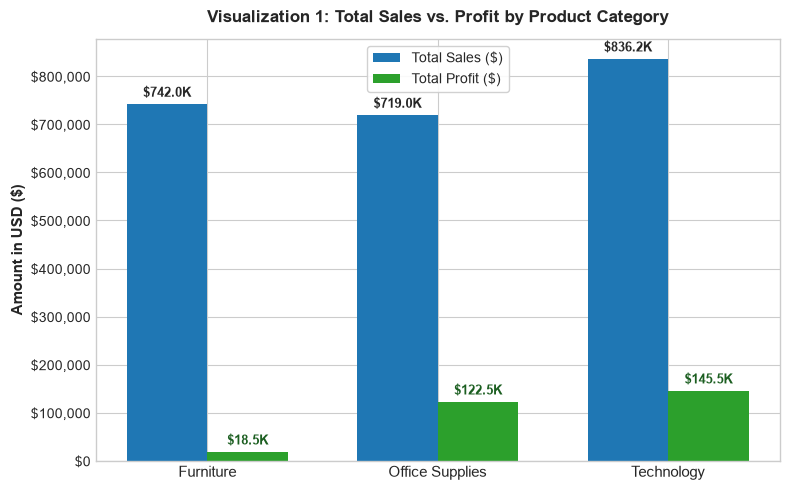

In [17]:
# Visualization 1: Total Sales vs. Profit by Category
cat_perf = df_analysis.groupby('Category')[['Sales', 'Profit']].sum().reset_index()

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(cat_perf['Category']))
width = 0.35

rects1 = ax.bar(x - width/2, cat_perf['Sales'], width, label='Total Sales ($)', color='#1F77B4')
rects2 = ax.bar(x + width/2, cat_perf['Profit'], width, label='Total Profit ($)', color='#2CA02C')

ax.set_ylabel('Amount in USD ($)', fontsize=11, fontweight='bold')
ax.set_title('Visualization 1: Total Sales vs. Profit by Product Category', fontsize=12, fontweight='bold', pad=12)
ax.set_xticks(x)
ax.set_xticklabels(cat_perf['Category'], fontsize=11)
ax.legend(frameon=True, facecolor='white', framealpha=0.9)
ax.yaxis.set_major_formatter('${x:,.0f}')

for bar in rects1:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 10000, f'${yval/1e3:,.1f}K', ha='center', va='bottom', fontsize=9, fontweight='bold')
for bar in rects2:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 10000, f'${yval/1e3:,.1f}K', ha='center', va='bottom', fontsize=9, fontweight='bold', color='#1B5E20')

plt.tight_layout()
plt.show()

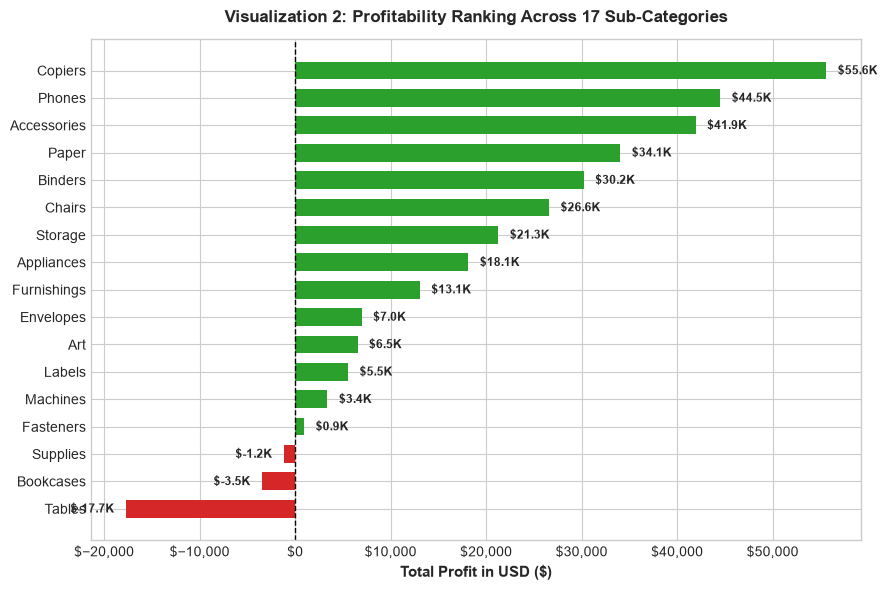

In [18]:
# Visualization 2: Profitability by Sub-Category (Color-Coded)
sub_perf = df_analysis.groupby('Sub-Category')['Profit'].sum().sort_values(ascending=True).reset_index()
colors = ['#D62728' if p < 0 else '#2CA02C' for p in sub_perf['Profit']]

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(sub_perf['Sub-Category'], sub_perf['Profit'], color=colors, height=0.65)

ax.axvline(0, color='black', linewidth=1, linestyle='--')
ax.set_xlabel('Total Profit in USD ($)', fontsize=11, fontweight='bold')
ax.set_title('Visualization 2: Profitability Ranking Across 17 Sub-Categories', fontsize=12, fontweight='bold', pad=12)
ax.xaxis.set_major_formatter('${x:,.0f}')

for bar in bars:
    w = bar.get_width()
    ha = 'left' if w >= 0 else 'right'
    offset = 1200 if w >= 0 else -1200
    ax.text(w + offset, bar.get_y() + bar.get_height()/2.0, f'${w/1e3:,.1f}K', ha=ha, va='center', fontsize=8.5, fontweight='bold')

plt.tight_layout()
plt.show()

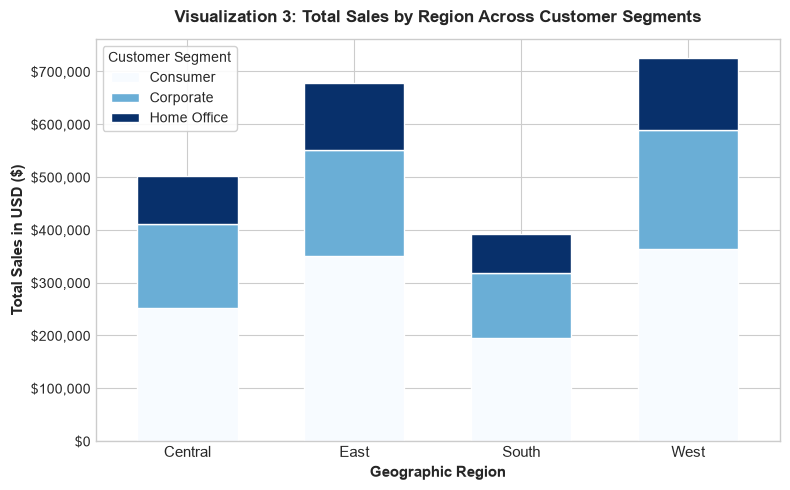

In [19]:
# Visualization 3: Regional Sales Breakdown by Customer Segment
reg_seg_pivot = df_analysis.groupby(['Region', 'Segment'])['Sales'].sum().unstack()

fig, ax = plt.subplots(figsize=(8, 5))
reg_seg_pivot.plot(kind='bar', stacked=True, ax=ax, colormap='Blues', edgecolor='white', width=0.6)

ax.set_ylabel('Total Sales in USD ($)', fontsize=11, fontweight='bold')
ax.set_xlabel('Geographic Region', fontsize=11, fontweight='bold')
ax.set_title('Visualization 3: Total Sales by Region Across Customer Segments', fontsize=12, fontweight='bold', pad=12)
ax.yaxis.set_major_formatter('${x:,.0f}')
ax.set_xticklabels(ax.get_xticklabels(), rotation=0, fontsize=11)
ax.legend(title='Customer Segment', frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.show()

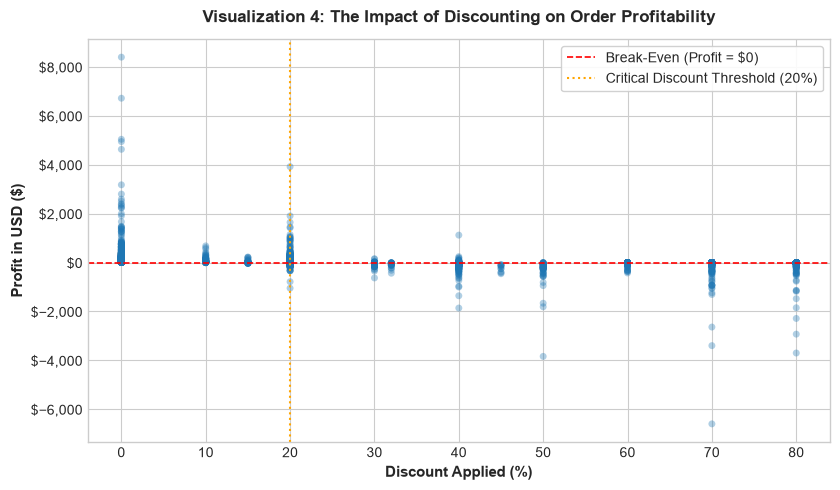

In [20]:
# Visualization 4: Impact of Discount on Profit
fig, ax = plt.subplots(figsize=(8.5, 5))

scatter = ax.scatter(df_analysis['Discount'] * 100, df_analysis['Profit'], alpha=0.35, color='#1F77B4', edgecolors='none', s=25)
ax.axhline(0, color='red', linestyle='--', linewidth=1.2, label='Break-Even (Profit = $0)')
ax.axvline(20, color='orange', linestyle=':', linewidth=1.5, label='Critical Discount Threshold (20%)')

ax.set_xlabel('Discount Applied (%)', fontsize=11, fontweight='bold')
ax.set_ylabel('Profit in USD ($)', fontsize=11, fontweight='bold')
ax.set_title('Visualization 4: The Impact of Discounting on Order Profitability', fontsize=12, fontweight='bold', pad=12)
ax.yaxis.set_major_formatter('${x:,.0f}')
ax.legend(frameon=True, facecolor='white', framealpha=0.9, loc='upper right')

plt.tight_layout()
plt.show()

## Step 7: Week 1 Analytical Summary
Addressing the four core project rubric questions:

### 1. What is the dataset about?
The `Sample_Superstore.csv` dataset contains transactional order records from a major multinational retail merchant across four United States geographic regions. The dataset captures the end-to-end purchasing lifecycle, including customer demographics, logistical shipping modes, geographic locations, product taxonomic classifications (Categories and Sub-Categories), commercial sales revenue, item order quantities, commercial discount percentages, and net generated profit/loss.

### 2. How many records and columns does it contain?
* **Total Records:** 10,800 raw records (including 9,994 valid business orders, 504 duplicate records, and 806 empty trailing lines).
* **Total Columns:** 21 attributes, comprising 15 categorical/text identifiers (`Order ID`, `Customer Name`, `Segment`, `City`, `State`, `Category`, `Sub-Category`, etc.) and 6 numerical variables (`Postal Code`, `Sales`, `Quantity`, `Discount`, `Profit`, `Row ID`).

### 3. What are the most important variables?
* **Primary Key & Relational Identifiers:** `Order ID`, `Customer ID`, `Product ID` (critical for Week 3 SQLite database schema design).
* **Financial Performance Indicators:** `Sales` (gross revenue), `Profit` (net bottom-line contribution), and `Discount` (pricing reduction rate).
* **Dimensional Aggregators:** `Category` / `Sub-Category` (product taxonomy), `Region` / `State` (geography), and `Segment` (market demographic).

### 4. What data quality issues did you discover, and how will they be resolved?
* **Empty Artifact Rows:** 806 rows contain null values across all operational fields. These will be dropped in Week 2 using `df.dropna(subset=['Sales', 'Order ID'])`.
* **Duplicate Rows:** 504 fully identical rows exist in the raw export, which will be eliminated via `df.drop_duplicates()`.
* **Missing Postal Codes:** 11 valid transactions in Burlington, Vermont lack postal codes and will be imputed with `05401`.
* **Data Type Formats:** `Order Date` and `Ship Date` will be cast from strings to `datetime64[ns]` objects to compute shipping turnaround times and enable temporal analytics in the Flask web app.